In [1]:
#import libraries 
import os 
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 
import ast
import seaborn as sns

#path for local caching 

file_path="data_jobs.parquet"

#loading data 
if not os.path.exists(file_path):
    dataset=load_dataset('lukebarousse/data_jobs') 
    df=dataset['train'].to_pandas()
    df.to_parquet(file_path)
else:
    df=pd.read_parquet(file_path)

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])
df['job_skills']=df['job_skills'].apply(lambda skill_list2: ast.literal_eval(skill_list2) if isinstance(skill_list2,str) else skill_list2 )




In [2]:
df_US=df[df['job_country']=='United States']

In [3]:
df_skills=df_US.explode('job_skills')

In [4]:
df_skills[['job_title','job_skills']]

,job_title,job_skills
0,Senior Clinical Data Engineer / Principal Clin...,NaN
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,python
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,c++
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,java
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,matlab
...,...,...
785692,Data Scientist- Hybrid Work Location,r
785703,Data Analyst - CRYPTOGRAPHY - Full-time,NaN
785705,Expert Business Data Analyst - Now Hiring,sql
785705,Expert Business Data Analyst - Now Hiring,python


In [5]:
df_skills_count=df_skills.groupby(['job_skills','job_title_short']).size()

df_skills_count=df_skills_count.reset_index(name='skill_count')
df_skills_count.sort_values(by='skill_count',ascending=False,inplace=True)
df_skills_count

,job_skills,job_title_short,skill_count
1209,python,Data Scientist,42379
1521,sql,Data Analyst,34452
1523,sql,Data Scientist,30034
455,excel,Data Analyst,27519
1243,r,Data Scientist,26022
...,...,...,...
1785,vue.js,Business Analyst,1
60,arch,Business Analyst,1
71,asana,Machine Learning Engineer,1
968,no-sql,Machine Learning Engineer,1


In [6]:
job_titles=df_skills_count['job_title_short'].unique().tolist()
job_titles=sorted(job_titles[:3])
job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

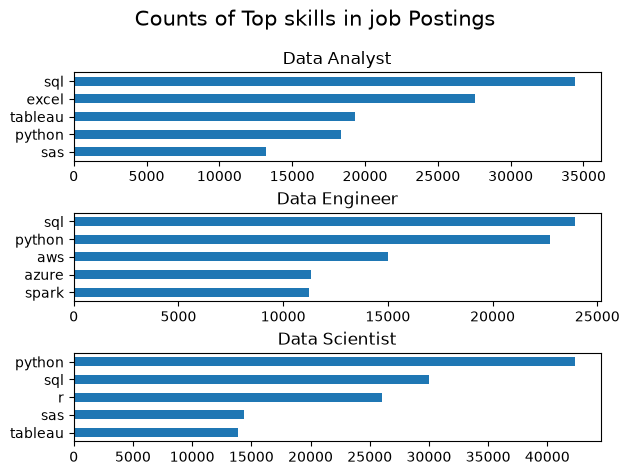

In [7]:
fig,ax=plt.subplots(len(job_titles),1) 

for i,job_title in enumerate(job_titles):
    df_plot=df_skills_count[df_skills_count['job_title_short']==job_title].head(5)
    df_plot.plot(kind='barh',x='job_skills',y='skill_count',ax=ax[i],title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)

fig.suptitle('Counts of Top skills in job Postings',fontsize=15)
fig.tight_layout(h_pad=0.5)
plt.show()

In [8]:
df_job_title_count=df_US['job_title_short'].value_counts().reset_index(name='jobs_total')

df_job_title_count

,job_title_short,jobs_total
0,Data Analyst,67816
1,Data Scientist,58830
2,Data Engineer,35080
3,Senior Data Scientist,12946
4,Senior Data Analyst,11791
5,Senior Data Engineer,9289
6,Business Analyst,7382
7,Software Engineer,1814
8,Machine Learning Engineer,921
9,Cloud Engineer,423


In [9]:
df_skills_perc=pd.merge(df_skills_count,df_job_title_count,how='left',on='job_title_short')
df_skills_perc['skills_perc']=df_skills_perc['skill_count']/df_skills_perc['jobs_total']*100
df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skills_perc
0,python,Data Scientist,42379,58830,72.036376
1,sql,Data Analyst,34452,67816,50.802171
2,sql,Data Scientist,30034,58830,51.052184
3,excel,Data Analyst,27519,67816,40.578919
4,r,Data Scientist,26022,58830,44.232534
...,...,...,...,...,...
1865,vue.js,Business Analyst,1,7382,0.013546
1866,arch,Business Analyst,1,7382,0.013546
1867,asana,Machine Learning Engineer,1,921,0.108578
1868,no-sql,Machine Learning Engineer,1,921,0.108578


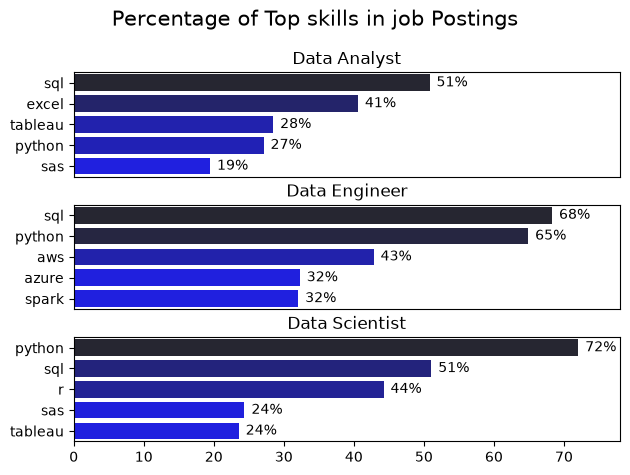

In [26]:
fig,ax=plt.subplots(len(job_titles),1) 

for i,job_title in enumerate(job_titles):
    df_plot=df_skills_perc[df_skills_perc['job_title_short']==job_title].head(5)
    # df_plot.plot(kind='barh',x='job_skills',y='skills_perc',ax=ax[i],title=job_title)
    sns.barplot(data=df_plot,x='skills_perc',y='job_skills',ax=ax[i],hue='skill_count',palette='dark:b_r')
    ax[i].set_title(job_title)
    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].get_legend().remove()
    ax[i].set_xlim(0,78) 

    for n,v in enumerate(df_plot['skills_perc']):
        ax[i].text(v+1,n,f'{v:.0f}%',va='center')
    if i !=len(job_titles)-1:
        ax[i].set_xticks([])

fig.suptitle('Percentage of Top skills in job Postings',fontsize=15)
fig.tight_layout(h_pad=0.5)
plt.show()